In [ ]:
import numpy as np
import importlib
import torch
import os
import psutil

import environment7
import agent8

importlib.reload(environment7)
importlib.reload(agent8)

from environment7 import *
from agent8 import *

MAX_EPISODES = 20000

device = "cuda" if torch.cuda.is_available() else "cpu"

env = Env4(use_distortion=True, use_sm=True)

MAX_STEPS = env.MaxSteps
state_dim = env.observation_space.shape[0]
num_rbs = env.N * env.M

agent = Agent1(state_dim, num_rbs, device=device)

# Only log reward
episode_rewards = []

for ep in range(MAX_EPISODES):

    state, _ = env.reset()

    total_reward = 0.0

    for step in range(MAX_STEPS):

        action = agent.get_action_explore(state)

        next_state, reward, terminated, truncated, _ = env.step(action)

        done = terminated or truncated

        agent.learn(state, action, reward, next_state, done)

        total_reward += reward
        state = next_state

        if done:
            break

    agent.end_episode()

    avg_reward = total_reward / (step + 1)
    episode_rewards.append(avg_reward)

    if (ep + 1) % 100 == 0:

        process = psutil.Process(os.getpid())
        ram = process.memory_info().rss / (1024**3)

        print(
            f"Ep {ep+1:5d} | "
            f"Reward {avg_reward:.4f} | "
            f"Eps {agent.epsilon:.3f} | "
            f"RAM {ram:.2f} GB"
        )

    # Save checkpoint every 500 episodes
    if (ep + 1) % 500 == 0:

        checkpoint = {
            "qnet_state_dict": agent.qnet.state_dict(),
            "qtarget_state_dict": agent.qtarget.state_dict(),
            "optimizer_state_dict": agent.optimizer.state_dict(),
            "epsilon": agent.epsilon,
            "step_count": agent.step_count,
            "episode_rewards": episode_rewards,
            "replay_buffer": agent.buffer,
        }

        SAVE_PATH = f"DIPSM1_ep{ep+1}.pth"
        torch.save(checkpoint, SAVE_PATH)

        print(f"Checkpoint saved: {SAVE_PATH}")

# Final checkpoint
checkpoint = {
    "qnet_state_dict": agent.qnet.state_dict(),
    "qtarget_state_dict": agent.qtarget.state_dict(),
    "optimizer_state_dict": agent.optimizer.state_dict(),
    "epsilon": agent.epsilon,
    "step_count": agent.step_count,
    "episode_rewards": episode_rewards,
    "replay_buffer": agent.buffer,
}

SAVE_PATH = "DIPSM1.pth"

torch.save(checkpoint, SAVE_PATH)

print("Saved at:", os.path.abspath(SAVE_PATH))

Ep   100 | Reward 1.3400 | Eps 0.951 | RAM 1.07 GB
Ep   200 | Reward 1.0409 | Eps 0.905 | RAM 1.09 GB
Ep   300 | Reward 1.9258 | Eps 0.861 | RAM 1.11 GB
Ep   400 | Reward 2.0736 | Eps 0.819 | RAM 1.13 GB
Ep   500 | Reward 2.6437 | Eps 0.779 | RAM 1.15 GB
Checkpoint saved: DIPSM1_ep500.pth
Ep   600 | Reward 2.1233 | Eps 0.741 | RAM 1.33 GB
Ep   700 | Reward 3.2477 | Eps 0.705 | RAM 1.35 GB
Ep   800 | Reward 2.9708 | Eps 0.670 | RAM 1.36 GB
Ep   900 | Reward 2.2009 | Eps 0.638 | RAM 1.38 GB
Ep  1000 | Reward 3.5156 | Eps 0.606 | RAM 1.39 GB
Checkpoint saved: DIPSM1_ep1000.pth
Ep  1100 | Reward 2.9558 | Eps 0.577 | RAM 1.53 GB
Ep  1200 | Reward 1.7724 | Eps 0.549 | RAM 1.53 GB
Ep  1300 | Reward 2.3241 | Eps 0.522 | RAM 1.53 GB
Ep  1400 | Reward 2.3980 | Eps 0.496 | RAM 1.54 GB
Ep  1500 | Reward 2.6124 | Eps 0.472 | RAM 1.54 GB
Checkpoint saved: DIPSM1_ep1500.pth
Ep  1600 | Reward 2.0750 | Eps 0.449 | RAM 1.54 GB
Ep  1700 | Reward 2.3132 | Eps 0.427 | RAM 1.54 GB
Ep  1800 | Reward 2.5283 |

In [ ]:
import numpy as np
import importlib
import torch
import os
import psutil

import environment7
import agent8

importlib.reload(environment7)
importlib.reload(agent8)

from environment7 import *
from agent8 import *

MAX_EPISODES = 20000
CKPT_PATH = "DIPSM1_ep20000.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"

env = Env4(use_distortion=True, use_sm=True)

MAX_STEPS = env.MaxSteps
state_dim = env.observation_space.shape[0]
num_rbs = env.N * env.M

agent = Agent1(state_dim, num_rbs, device=device)

# =====================================================
# Resume training if checkpoint exists
# =====================================================
if os.path.exists(CKPT_PATH):

    print(f"Loading checkpoint: {CKPT_PATH}")

    checkpoint = torch.load(CKPT_PATH, map_location=device)

    agent.qnet.load_state_dict(checkpoint["qnet_state_dict"])
    agent.qtarget.load_state_dict(checkpoint["qtarget_state_dict"])
    agent.optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    agent.epsilon = checkpoint["epsilon"]
    agent.step_count = checkpoint["step_count"]

    episode_rewards = checkpoint["episode_rewards"]
    agent.buffer = checkpoint["replay_buffer"]

    start_episode = len(episode_rewards)

    print(f"Resuming from episode {start_episode}")

else:

    print("No checkpoint found. Starting from scratch.")

    episode_rewards = []
    start_episode = 0

# =====================================================
# Training
# =====================================================
for ep in range(start_episode, MAX_EPISODES):

    state, _ = env.reset()

    total_reward = 0.0

    for step in range(MAX_STEPS):

        action = agent.get_action_explore(state)

        next_state, reward, terminated, truncated, _ = env.step(action)

        done = terminated or truncated

        agent.learn(state, action, reward, next_state, done)

        total_reward += reward
        state = next_state

        if done:
            break

    agent.end_episode()

    avg_reward = total_reward / (step + 1)
    episode_rewards.append(avg_reward)

    if (ep + 1) % 100 == 0:

        process = psutil.Process(os.getpid())
        ram = process.memory_info().rss / (1024**3)

        print(
            f"Ep {ep+1:5d} | "
            f"Reward {avg_reward:.4f} | "
            f"Eps {agent.epsilon:.3f} | "
            f"RAM {ram:.2f} GB"
        )

    # =====================================================
    # Save checkpoint every 500 episodes
    # =====================================================
    if (ep + 1) % 500 == 0:

        checkpoint = {
            "qnet_state_dict": agent.qnet.state_dict(),
            "qtarget_state_dict": agent.qtarget.state_dict(),
            "optimizer_state_dict": agent.optimizer.state_dict(),
            "epsilon": agent.epsilon,
            "step_count": agent.step_count,
            "episode_rewards": episode_rewards,
            "replay_buffer": agent.buffer,
        }

        SAVE_PATH = f"DIPSM1_ep{ep+1}.pth"

        torch.save(checkpoint, SAVE_PATH)

        print(f"Checkpoint saved: {SAVE_PATH}")

# =====================================================
# Final checkpoint
# =====================================================
checkpoint = {
    "qnet_state_dict": agent.qnet.state_dict(),
    "qtarget_state_dict": agent.qtarget.state_dict(),
    "optimizer_state_dict": agent.optimizer.state_dict(),
    "epsilon": agent.epsilon,
    "step_count": agent.step_count,
    "episode_rewards": episode_rewards,
    "replay_buffer": agent.buffer,
}

SAVE_PATH = "DIPSM1.pth"

torch.save(checkpoint, SAVE_PATH)

print("Saved at:", os.path.abspath(SAVE_PATH))

Loading checkpoint: DIPSM1_ep7000.pth


/tmp/ipykernel_81/655062721.py:36: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CKPT_PATH, map_location=device)


Resuming from episode 7000
Ep  7100 | Reward 1.8707 | Eps 0.050 | RAM 1.47 GB
Ep  7200 | Reward 3.2263 | Eps 0.050 | RAM 1.47 GB
Ep  7300 | Reward 2.6799 | Eps 0.050 | RAM 1.47 GB
Ep  7400 | Reward 3.0632 | Eps 0.050 | RAM 1.47 GB
Ep  7500 | Reward 3.6189 | Eps 0.050 | RAM 1.47 GB
Checkpoint saved: DIPSM1_ep7500.pth
Ep  7600 | Reward 2.8788 | Eps 0.050 | RAM 1.51 GB
Ep  7700 | Reward 3.7208 | Eps 0.050 | RAM 1.51 GB
Ep  7800 | Reward 2.3950 | Eps 0.050 | RAM 1.52 GB
Ep  7900 | Reward 1.9370 | Eps 0.050 | RAM 1.52 GB
Ep  8000 | Reward 2.7386 | Eps 0.050 | RAM 1.52 GB
Checkpoint saved: DIPSM1_ep8000.pth
Ep  8100 | Reward 2.3522 | Eps 0.050 | RAM 1.52 GB
Ep  8200 | Reward 3.4711 | Eps 0.050 | RAM 1.52 GB
Ep  8300 | Reward 4.5790 | Eps 0.050 | RAM 1.52 GB
Ep  8400 | Reward 1.8922 | Eps 0.050 | RAM 1.52 GB
Ep  8500 | Reward 4.3517 | Eps 0.050 | RAM 1.52 GB
Checkpoint saved: DIPSM1_ep8500.pth
Ep  8600 | Reward 3.1874 | Eps 0.050 | RAM 1.52 GB
Ep  8700 | Reward 1.8572 | Eps 0.050 | RAM 1.52 G

/tmp/ipykernel_3290/1320169838.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(


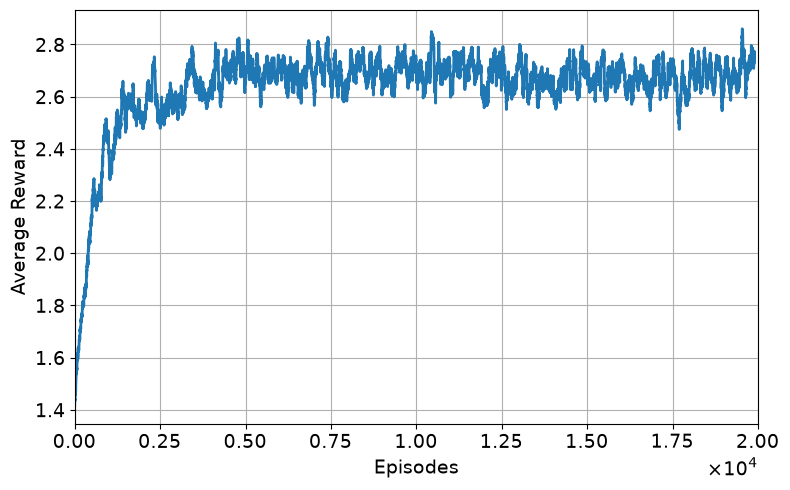

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# Load checkpoint
# ==========================================================
ckpt = torch.load(
    "DIPSM1_ep20000.pth",
    map_location="cpu"
)

reward = np.array(ckpt["episode_rewards"])
# throughput = np.array(ckpt["episode_final_DR"])
# ee = np.array(ckpt["episode_final_EE"])
# pru = np.array(ckpt["episode_avg_Pru"])

# ==========================================================
# Moving-average smoothing
# ==========================================================
window = 100

def smooth(x, w):
    if len(x) < w:
        return x
    return np.convolve(x, np.ones(w)/w, mode="valid")

reward_s = smooth(reward, window)


from matplotlib.ticker import ScalarFormatter

plt.figure(figsize=(8,5))

plt.plot(reward_s, linewidth=2)

plt.xlabel("Episodes", fontsize=14)
plt.ylabel("Average Reward", fontsize=14)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

ax = plt.gca()
plt.xlim(0, 20000)
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((3,3))
ax.xaxis.set_major_formatter(formatter)

ax.ticklabel_format(style='sci', axis='x', scilimits=(3,4))

ax.xaxis.get_offset_text().set_fontsize(14)

plt.grid(True)
plt.tight_layout()
plt.savefig("reward_convergence.pdf", format="pdf", bbox_inches="tight")
plt.show()

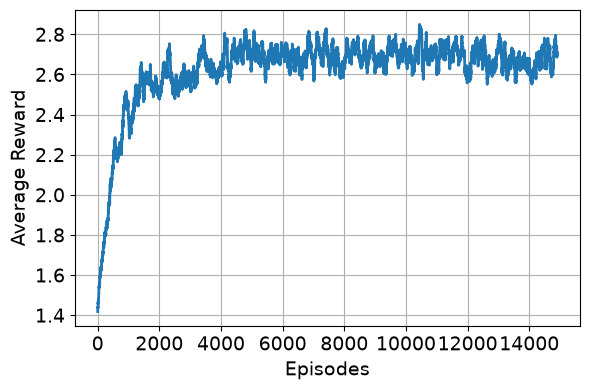

In [3]:
plt.figure(figsize=(6, 4))

plt.plot(reward_s, linewidth=2)

plt.xlabel("Episodes", fontsize=14)
plt.ylabel("Average Reward", fontsize=14)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.grid(True)

plt.tight_layout()
plt.show()